<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup complete
           TV      Radio  Newspaper      Sales
0  233.317034  15.096370  73.858039  15.333103
1  134.469140  45.922095  31.715317  16.806730
2  258.286386  39.064702  89.001946  25.172094
3  210.723569   5.529421  59.383055  15.814007
4   32.782318  49.851733  12.602634  13.478140


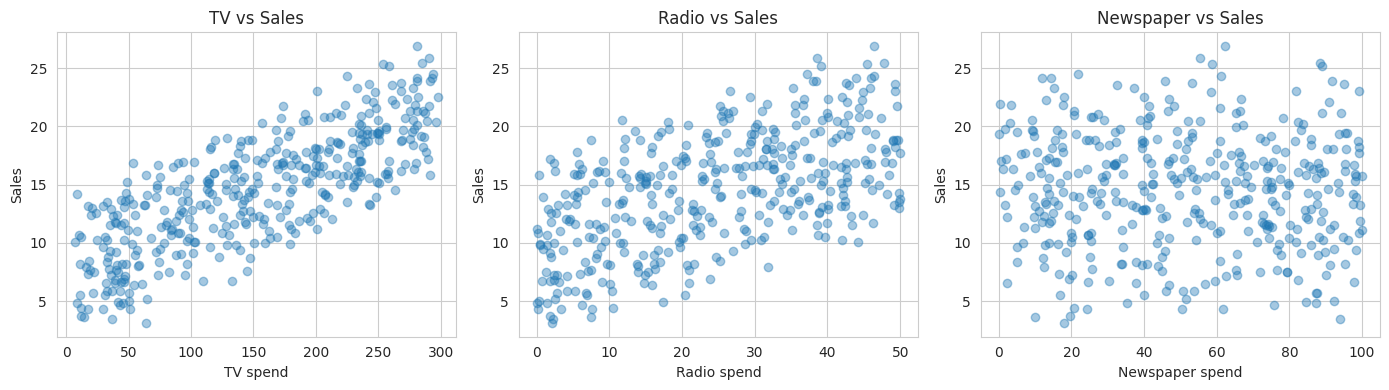

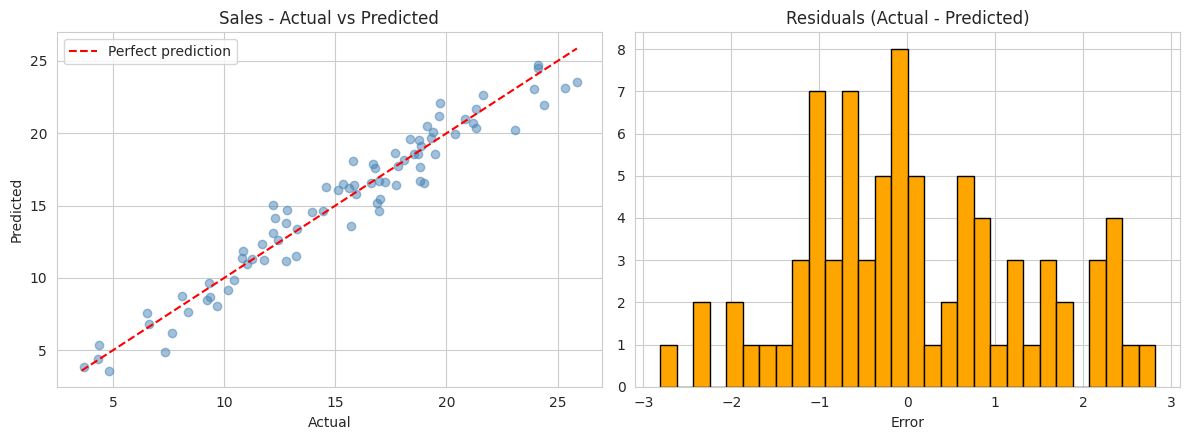

R2 = 0.943 | RMSE = 1.262 | MAE = 1.009


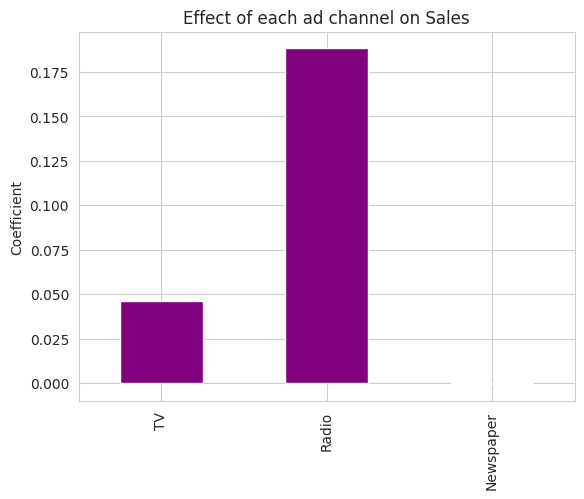

    TV  Radio  Newspaper  Predicted_Sales
0  150     20         30            13.61
1  200     25         30            16.85
2  250     30         30            20.08
3  300     35         30            23.32


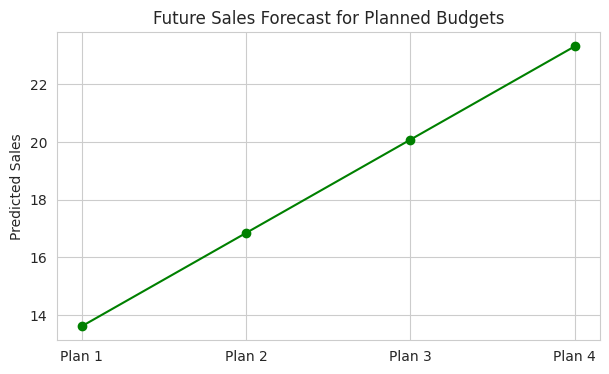

In [1]:
# ---------- Common imports and helper functions ----------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris, load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron as SkPerceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, auc,
                             r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
rng = np.random.default_rng(42)

def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_reg(y_true, y_pred, title):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_true, y_pred, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax[0].plot(lims, lims, "r--", label="Perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title(title); ax[0].legend()
    ax[1].hist(y_true - y_pred, bins=30, color="orange", edgecolor="black")
    ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlabel("Error")
    plt.tight_layout(); plt.show()
    print(f"R2 = {r2_score(y_true, y_pred):.3f} | RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f}")

def plot_importance(names, values, title):
    s = pd.Series(values, index=names).sort_values()
    s.plot(kind="barh", figsize=(7, 4), color="teal"); plt.title(title); plt.xlabel("Importance")
    plt.tight_layout(); plt.show()

def plot_boundary(model, X2, y, xlabel, ylabel, class_names, title):
    # model must already be trained on the 2 features in X2
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    for i, c in enumerate(class_names):
        plt.scatter(X2[y == i, 0], X2[y == i, 1], label=c, edgecolor="k")
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()
print("Setup complete")

n = 400
df = pd.DataFrame({"TV": rng.uniform(5, 300, n), "Radio": rng.uniform(0, 50, n), "Newspaper": rng.uniform(0, 100, n)})
df["Sales"] = 3 + 0.045*df.TV + 0.19*df.Radio + 0.002*df.Newspaper + rng.normal(0, 1.2, n)
print(df.head())

X = df[["TV", "Radio", "Newspaper"]]; y = df["Sales"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_tr, y_tr); pred = model.predict(X_te)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, X.columns):
    a.scatter(df[c], df["Sales"], alpha=0.4); a.set_xlabel(c + " spend"); a.set_ylabel("Sales"); a.set_title(f"{c} vs Sales")
plt.tight_layout(); plt.show()

plot_reg(y_te, pred, "Sales - Actual vs Predicted")
pd.Series(model.coef_, index=X.columns).plot(kind="bar", color="purple", title="Effect of each ad channel on Sales"); plt.ylabel("Coefficient"); plt.show()

# ---- Future sales for planned budgets ----
future = pd.DataFrame({"TV": [150, 200, 250, 300], "Radio": [20, 25, 30, 35], "Newspaper": [30, 30, 30, 30]})
future["Predicted_Sales"] = model.predict(future[["TV", "Radio", "Newspaper"]])
print(future.round(2))

plt.figure(figsize=(7, 4))
plt.plot(range(1, 5), future["Predicted_Sales"], marker="o", color="green")
plt.xticks(range(1, 5), [f"Plan {i}" for i in range(1, 5)]); plt.ylabel("Predicted Sales")
plt.title("Future Sales Forecast for Planned Budgets"); plt.grid(True); plt.show()